# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

In [2]:
# some helper functions and classes (no need to check them now)
import sys
from pathlib import Path

# Assuming the working directory is root/part1 or root/part2
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

In [3]:
from tqdm.notebook import tqdm
from datasets import load_dataset
from collections import Counter
from collections import OrderedDict
import sys
from pathlib import Path
import numpy as np

#Loading our training corpus
dataset = load_dataset("fancyzhx/ag_news")
corpus = dataset["train"]["text"]
results_folder = Path("./results")
print(dataset)

agnews_outcome_space = part1.clslib.NamedClasses(['world', 'sports', 'business', 'tech/sci-fi'])
vocab_size = 1000
min_frequency = 2
tokenizer = part1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [4]:
%%time
my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

CPU times: total: 1.78 s
Wall time: 1.79 s


### Exploratory Data Analysis

In [5]:
from collections import Counter

# Get the labels from the training set (AG News uses integers: 0, 1, 2, 3)
train_labels = dataset["train"]["label"]

# Map integers back to AG News category names
label_names = ['world', 'sports', 'business', 'tech/sci-fi']
named_labels = [label_names[label_id] for label_id in train_labels]

# Count frequencies
label_counts = Counter(named_labels)

print(f"Total number of categories: {len(label_counts)}")
print("\nSamples per category:")
for category, count in label_counts.items():
    print(f"  - {category}: {count:,} samples")

# Check balance
counts_list = list(label_counts.values())
if max(counts_list) - min(counts_list) < 100:
    print("\n👉 The dataset is perfectly balanced!")
else:
    print("\n👉 The dataset has slight imbalances across categories.")

Total number of categories: 4

Samples per category:
  - business: 30,000 samples
  - tech/sci-fi: 30,000 samples
  - sports: 30,000 samples
  - world: 30,000 samples

👉 The dataset is perfectly balanced!


In [6]:
import numpy as np

# Extract texts
train_texts = dataset["train"]["text"]

# Compute lengths
char_lengths = [len(text) for text in train_texts]
word_lengths = [len(text.split()) for text in train_texts]

print("=== Text Length Statistics ===")
print(f"Characters per sample -> Mean: {np.mean(char_lengths):.1f} | Median: {np.median(char_lengths):.0f} | Min: {min(char_lengths)} | Max: {max(char_lengths)}")
print(f"Words per sample      -> Mean: {np.mean(word_lengths):.1f} | Median: {np.median(word_lengths):.0f} | Min: {min(word_lengths)} | Max: {max(word_lengths)}")

=== Text Length Statistics ===
Characters per sample -> Mean: 236.5 | Median: 232 | Min: 100 | Max: 1012
Words per sample      -> Mean: 37.8 | Median: 37 | Min: 8 | Max: 177


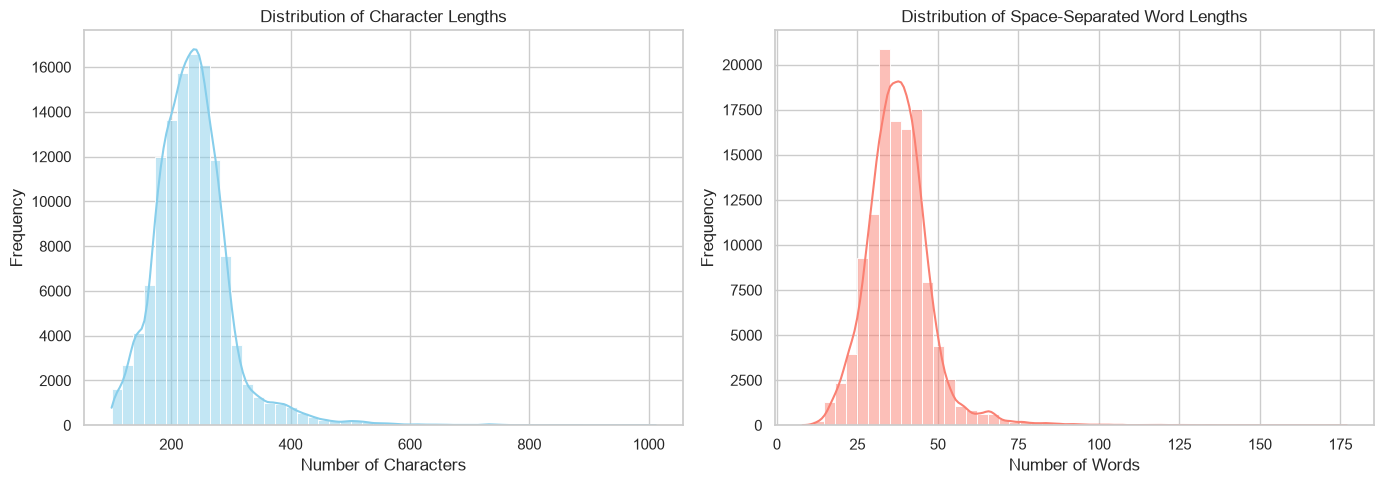

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Character Length Distribution
sns.histplot(char_lengths, bins=50, color="skyblue", kde=True, ax=axes[0])
axes[0].set_title("Distribution of Character Lengths")
axes[0].set_xlabel("Number of Characters")
axes[0].set_ylabel("Frequency")

# Plot Word Length Distribution
sns.histplot(word_lengths, bins=50, color="salmon", kde=True, ax=axes[1])
axes[1].set_title("Distribution of Space-Separated Word Lengths")
axes[1].set_xlabel("Number of Words")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

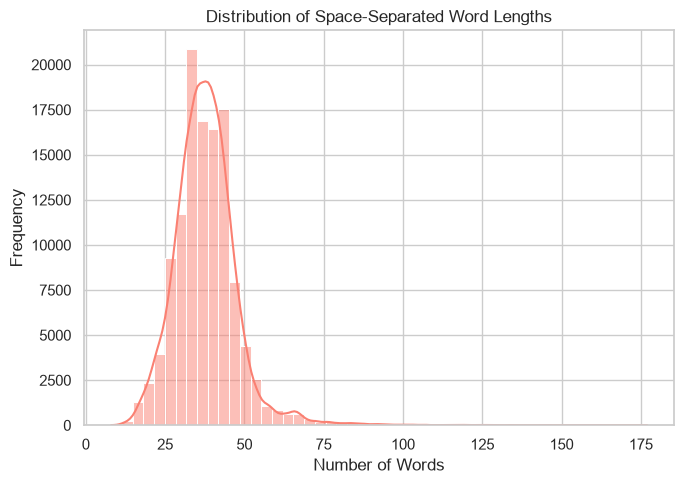

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(7, 5))  # Single figure and axis

# Plot Word Length Distribution
sns.histplot(word_lengths, bins=50, color="salmon", kde=True, ax=ax)
ax.set_title("Distribution of Space-Separated Word Lengths")
ax.set_xlabel("Number of Words")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [9]:
from tokenizers import Tokenizer

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

### Tokenization Tests

Training tokenizer on 100 sentences with fixed vocab_size=1000...


d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


   -> Actual Vocab Achieved: 1000 | Accuracy: 0.8433
Training tokenizer on 500 sentences with fixed vocab_size=1000...


d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


   -> Actual Vocab Achieved: 1000 | Accuracy: 0.8498
Training tokenizer on 1,000 sentences with fixed vocab_size=1000...


d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


... (3 outputs left out)

d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


   -> Actual Vocab Achieved: 1000 | Accuracy: 0.8548
Training tokenizer on 120,000 sentences with fixed vocab_size=1000...


d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


   -> Actual Vocab Achieved: 1000 | Accuracy: 0.8556


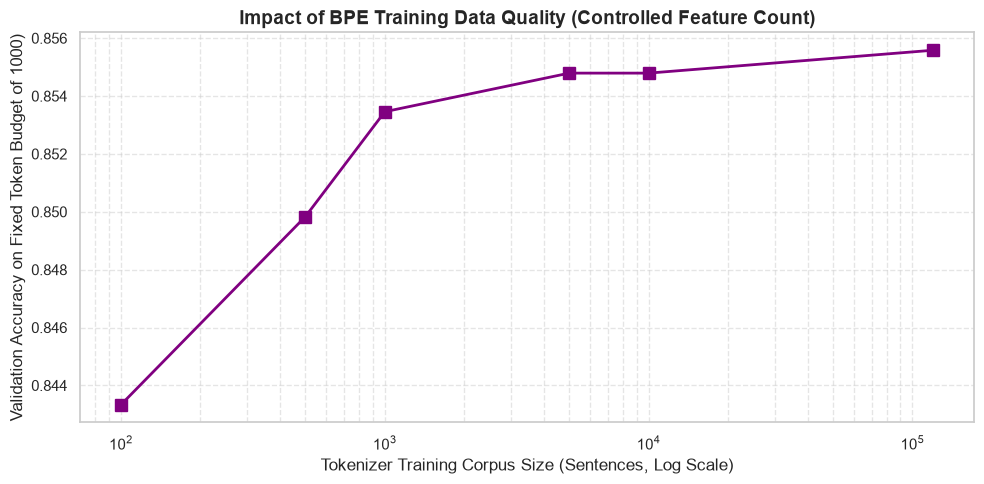

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

FIXED_VOCAB_SIZE = 1000
sentence_sizes = [100, 500, 1000, 5000, 10000, len(corpus)]

controlled_results = []

train_data = my_cross_validation_sets[0][0]["training"]
val_data = my_cross_validation_sets[0][0]["validation"]
val_texts = [text for text, gold_label in val_data]
val_labels = [gold_label for text, gold_label in val_data]

for size in sentence_sizes:
    print(f"Training tokenizer on {size:,} sentences with fixed vocab_size={FIXED_VOCAB_SIZE}...")
    
    subset_corpus = corpus[:size]
    
    # We train tokenizer with a fixed target vocab size
    tokenizer = part1.experiment.train_tokenizer(
        subset_corpus, 
        vocab_size=FIXED_VOCAB_SIZE, 
        min_frequency=min_frequency
    )
    
    actual_vocab_size = len(tokenizer.get_vocab())
    vocab = tokenizer.get_vocab()
    
    # We fit model using the basic TokenIndicator
    encoder = TokenIndicator(tokenizer)
    model = part1.loglin.fit(train_data, encoder, save_to=None)
    
    # Evaluate accuracy
    preds = part1.loglin.predict(val_texts, model, encoder)
    acc = accuracy_score(val_labels, preds)
    
    controlled_results.append((size, actual_vocab_size, acc, vocab))
    print(f"   -> Actual Vocab Achieved: {actual_vocab_size} | Accuracy: {acc:.4f}")

# ==========================================
# Plotting the Controlled Experiment
# ==========================================
sizes, vocabs, accs, vocab = zip(*controlled_results)

plt.figure(figsize=(10, 5))
plt.plot(sizes, accs, marker='s', linestyle='-', color='purple', linewidth=2, markersize=8)
plt.xscale('log')
plt.xlabel('Tokenizer Training Corpus Size (Sentences, Log Scale)', fontsize=12)
plt.ylabel(f'Validation Accuracy on Fixed Token Budget of {FIXED_VOCAB_SIZE})', fontsize=12)
plt.title('Impact of BPE Training Data Quality (Controlled Feature Count)', fontsize=14, fontweight='bold')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [11]:
sizes, vocabs, accs, vocab_list = zip(*controlled_results)

# Index 0 is 100 sentences. Index -1 is the full corpus
small_size, small_vocab = sizes[0], vocab_list[0]
full_size, full_vocab = sizes[-1], vocab_list[-1]

added_tokens = set(full_vocab.keys()) - set(small_vocab.keys())
lost_tokens = set(small_vocab.keys()) - set(full_vocab.keys())

print(f"\n" + "="*70)
print(f"Extreme Comparison: {small_size:,} sentences vs. Full Corpus ({full_size:,})")
print(f"="*70)
print(f"Vocab Size (100 sentences): {len(small_vocab)} | Vocab Size (Full): {len(full_vocab)}")
print(f"Tokens Added: {len(added_tokens):,}  |  Tokens Lost: {len(lost_tokens):,}")

if added_tokens:
    sample_added = sorted(list(added_tokens), key=lambda x: (-len(x), x))[:20]
    print(f"\n  • Sample NEW tokens learned by the full corpus:\n    {sample_added}")
    
if lost_tokens:
    sample_lost = sorted(list(lost_tokens), key=lambda x: (-len(x), x))[:20]
    print(f"\n  • Sample LOST tokens (dropped noise/artifacts from 100-sentence model):\n    {sample_lost}")


Extreme Comparison: 100 sentences vs. Full Corpus (120,000)
Vocab Size (100 sentences): 1000 | Vocab Size (Full): 1000
Tokens Added: 407  |  Tokens Lost: 407

  • Sample NEW tokens learned by the full corpus:
    ['▁government', '▁Microsoft', '▁President', '▁Wednesday', '▁announced', '▁officials', '▁president', '▁yesterday', 'overnment', '▁American', '▁European', '▁Internet', '▁Saturday', '▁Thursday', '▁official', '▁reported', '▁security', '▁software', 'ednesday', 'esterday']

  • Sample LOST tokens (dropped noise/artifacts from 100-sentence model):
    ['▁researchers', '▁Scientists', '▁technology', "▁company's", '▁customers', '▁interview', 'cientists', '▁Autodesk', "▁Google's", '▁Japanese', '▁election', '▁wireless', 'earchers', 'resident', '▁Central', '▁Philipp', '▁Playboy', '▁Russian', '▁auction', '▁develop']


### Testing out other ways to extract features

##### TF-IDF

In [12]:
import numpy as np
from collections import Counter
from tokenizers import Tokenizer

class TfIdfEncoder(Encoder):
    def __init__(self, tokenizer: Tokenizer, corpus_texts: list[str]):
        self.tokenizer = tokenizer
        self.vocab_size = len(tokenizer.get_vocab())
        
        # Compute Document Frequencies (DF) across the training corpus
        doc_counts = Counter()
        num_docs = len(corpus_texts)
        
        for text in corpus_texts:
            # Use unique token IDs per document for IDF calculation
            token_ids = set(self.tokenizer.encode(text).ids)
            for tid in token_ids:
                if tid < self.vocab_size:
                    doc_counts[tid] += 1
        
        # Compute Smoothed IDF
        # IDF(t) = log((1 + N) / (1 + DF(t))) + 1
        self.idf = np.zeros(self.vocab_size)
        for tid in range(self.vocab_size):
            df = doc_counts.get(tid, 0)
            self.idf[tid] = np.log((1.0 + num_docs) / (1.0 + df)) + 1.0

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return self.vocab_size

    def __call__(self, x: str) -> np.array:
        """Represent x as a D-dimensional TF-IDF vector"""
        token_ids = self.tokenizer.encode(x).ids
        
        # Count raw occurrences of each token in this specific document (Term Freq)
        token_counts = Counter(token_ids)
        
        vector = np.zeros(self.vocab_size)
        for tid, count in token_counts.items():
            if tid < self.vocab_size:
                # TF-IDF = (Raw Term Frequency) * IDF
                vector[tid] = count * self.idf[tid]
                
        # L2 Norm
        norm = np.linalg.norm(vector)
        if norm > 0:
            vector = vector / norm
            
        return vector

In [13]:
%%time
# Extract just the text strings from training set
training_texts = [text for text, gold_label in my_cross_validation_sets[0][0]["training"]]
# Initialize the TF-IDF encoder
tfidf_encoder = TfIdfEncoder(tokenizer, training_texts)

CPU times: total: 10.1 s
Wall time: 10.5 s


In [14]:
%%time
logistic_model = part1.loglin.fit(my_cross_validation_sets[0][0]["training"], tfidf_encoder, save_to=None)  # remember to index datasets by [run][fold]

d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


CPU times: total: 18.4 s
Wall time: 19 s


In [15]:
%%time
# for the model trained on the first fold (less than 10s)
logistic_predictions = part1.loglin.predict([text for text, gold_label in my_cross_validation_sets[0][0]["validation"]], logistic_model, tfidf_encoder)  # remember to index datasets by [run][fold]

CPU times: total: 3.44 s
Wall time: 3.46 s


In [16]:
%%time
from sklearn.metrics import accuracy_score

# again, for the model trained on the first fold 
logistic_accuracy = accuracy_score(
    [gold_label for text, gold_label in my_cross_validation_sets[0][0]["validation"]],  # remember to index datasets by [run][fold]
    logistic_predictions
)
print(f"Accuracy: {logistic_accuracy:.4f}")

Accuracy: 0.8630
CPU times: total: 15.6 ms
Wall time: 12.9 ms


#### Augmented with Bigrams

In [17]:
import numpy as np
from collections import Counter
from tokenizers import Tokenizer

class ConstrainedBigramEncoder(Encoder):
    def __init__(self, tokenizer: Tokenizer, corpus_texts: list[str], max_features: int = 1000):
        self.tokenizer = tokenizer
        self.max_features = max_features
        
        # Count frequencies of ALL unigrams and bigrams across the training corpus
        feature_counts = Counter()
        
        for text in corpus_texts:
            token_ids = self.tokenizer.encode(text).ids
            
            # unigrams
            for tid in token_ids:
                feature_counts[(tid,)] += 1
                
            # bigrams
            for i in range(len(token_ids) - 1):
                feature_counts[(token_ids[i], token_ids[i+1])] += 1
                
        # Select only the top `max_features` most frequent features
        most_common_features = feature_counts.most_common(self.max_features)
        
        # Build the index mapping
        self.feature_to_idx = {feature: idx for idx, (feature, count) in enumerate(most_common_features)}
        
        print(f"Feature space constrained to top {len(self.feature_to_idx):,} features")

    def __len__(self) -> int:
        """Dimensionality of the representation space (fixed to max_features)"""
        return len(self.feature_to_idx)

    def __call__(self, x: str) -> np.array:
        """Represent x as a 1,000-dimensional vector of top unigrams and bigrams"""
        token_ids = self.tokenizer.encode(x).ids
        
        document_features = []
        
        # Collect unigrams
        for tid in token_ids:
            document_features.append((tid,))
            
        # Collect bigrams
        for i in range(len(token_ids) - 1):
            document_features.append((token_ids[i], token_ids[i+1]))
            
        # Count frequencies for features present in this document
        feature_counts = Counter(document_features)
        
        vector = np.zeros(len(self))
        for feature, count in feature_counts.items():
            if feature in self.feature_to_idx:
                vector[self.feature_to_idx[feature]] = count
                
        return vector

In [18]:
training_texts = [text for text, gold_label in my_cross_validation_sets[0][0]["training"]]

constrained_bigram_encoder = ConstrainedBigramEncoder(tokenizer, training_texts, max_features=1000)

logistic_model_constrained_bigram = part1.loglin.fit(
    my_cross_validation_sets[0][0]["training"], 
    constrained_bigram_encoder, 
    save_to=None
)

# Evaluate
validation_data = my_cross_validation_sets[0][0]["validation"]
val_texts = [text for text, gold_label in validation_data]
val_labels = [gold_label for text, gold_label in validation_data]

predictions = part1.loglin.predict(val_texts, logistic_model_constrained_bigram, constrained_bigram_encoder)

from sklearn.metrics import accuracy_score
accuracy = accuracy_score(val_labels, predictions)
print(f"Bigram Model Accuracy: {accuracy:.4f}")

Feature space constrained to top 1,000 features


d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Bigram Model Accuracy: 0.8590


### ...

In [19]:
%%time
# train using the first fold (less than 1 min)
# (don't mind the warning about convergence)
token_indicator_encoder = TokenIndicator(tokenizer)
logistic_model = part1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)  # remember to index datasets by [run][fold]

d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


CPU times: total: 1min 2s
Wall time: 1min 5s


d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [20]:
%%time
# for the model trained on the first fold (less than 10s)
logistic_predictions = part1.loglin.predict([text for text, gold_label in my_cross_validation_sets[0][0]["validation"]], logistic_model, token_indicator_encoder)  # remember to index datasets by [run][fold]

CPU times: total: 10.6 s
Wall time: 11 s


In [21]:
def get_average_token_length(texts, tokenizer):
    token_lengths = []
    for text in texts:
        # Encode the text and count the number of token IDs produced
        num_tokens = len(tokenizer.encode(text).ids)
        token_lengths.append(num_tokens)
        
    avg_length = sum(token_lengths) / len(token_lengths)
    max_length = max(token_lengths)
    min_length = min(token_lengths)
    
    print(f"--- Token Length Statistics ---")
    print(f"Average length: {avg_length:.2f} tokens")
    print(f"Maximum length: {max_length} tokens")
    print(f"Minimum length: {min_length} tokens")
    
    return token_lengths

# Example usage on your validation text strings:
val_texts = [text for text, gold_label in my_cross_validation_sets[0][0]["validation"]]
token_lens = get_average_token_length(val_texts, tokenizer)

--- Token Length Statistics ---
Average length: 91.95 tokens
Maximum length: 492 tokens
Minimum length: 29 tokens


In [22]:
%%time
from sklearn.metrics import accuracy_score

# again, for the model trained on the first fold 
logistic_accuracy = accuracy_score(
    [gold_label for text, gold_label in my_cross_validation_sets[0][0]["validation"]],  # remember to index datasets by [run][fold]
    logistic_predictions
)
print(f"Accuracy: {logistic_accuracy:.4f}")

Accuracy: 0.8556
CPU times: total: 15.6 ms
Wall time: 13.6 ms


In [23]:
%%time
my_classifiers = OrderedDict()

my_classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    my_classifiers['logistic_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:14

CPU times: total: 6min
Wall time: 6min 12s


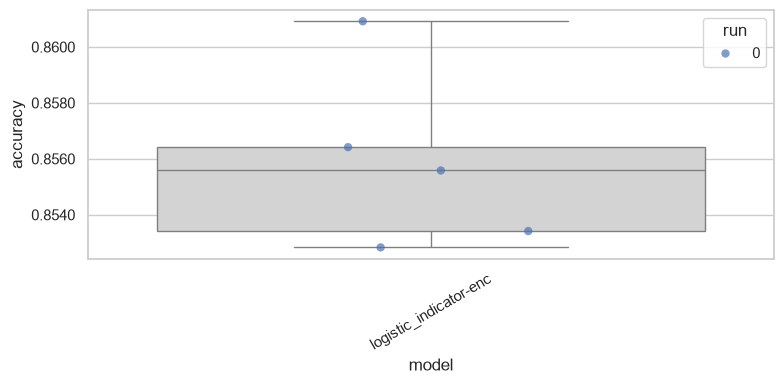

In [24]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

In [25]:
class BagOfWords(Encoder):
    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
    def __len__(self) -> int:
            """Dimensionality of the representation space"""
            return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(self.tokenizer.encode(x).ids)
    
        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        for id in unique_token_ids:
            vector[id] += 1
        return vector

bow_encoder = BagOfWords(tokenizer)

In [26]:
%%time
try:

    my_classifiers['logistic_bow-enc'] = []
    for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
        run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
        my_classifiers['logistic_bow-enc'].append(
            part1.experiment.cross_validation_experiment(        
                data_splits=my_cross_validation_sets[run],
                outcome_space=agnews_outcome_space,
                encoder=bow_encoder, 
                model_option='logistic',
                save_to=run_folder,
                loglin_args={
                    'max_iter': 100
                }
            )
        )
except ImportError:
    print("You need your own implementation")


  0%|          | 0/5 [00:00<?, ?it/s]

d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:14

CPU times: total: 6min 7s
Wall time: 6min 20s


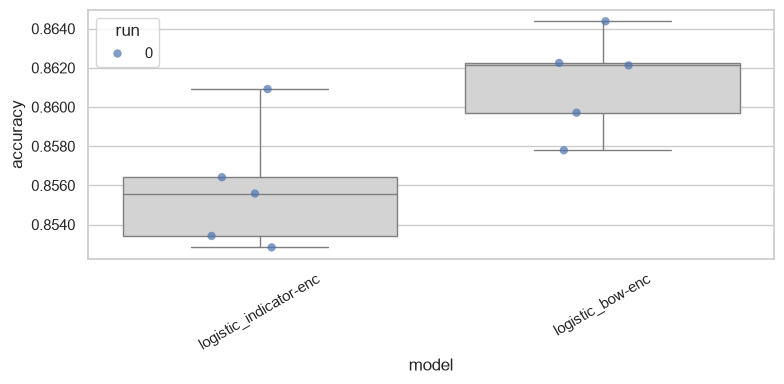

In [27]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

In [28]:

%%time
import torch
# about 2 minutes
metrics_for_all, best_epoch, best_preds = part1.smlp.train_neural_network_model(
    my_cross_validation_sets[0][0]["training"],  # remember to index datasets by [run][fold]
    my_cross_validation_sets[0][0]["validation"],  # remember to index datasets by [run][fold]
    num_classes=len(agnews_outcome_space),
    encoder=token_indicator_encoder, 
    save_to=f'{results_folder}/tmpmodel',
    hidden_dim=128, 
    dropout=0.1, 
    batch_size=64, 
    learning_rate=1e-4, 
    weight_decay=1e-4, 
    num_epochs=10,
    device='cuda'
)

Transforming documents...
Document transformation done! Time taken: 52.208 seconds
Dataloader done! Time taken: 1.579 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

d:\Assignments\nlp1-student\part1\smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:255.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
d:\Assignments\nlp1-student\part1\smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.7509 | train acc: 0.7541 | val loss: 0.4779 | val acc: 0.8385
Epoch 02 | train loss: 0.4533 | train acc: 0.8434 | val loss: 0.4287 | val acc: 0.8498
Epoch 03 | train loss: 0.4192 | train acc: 0.8536 | val loss: 0.4129 | val acc: 0.8535
Epoch 04 | train loss: 0.4045 | train acc: 0.8565 | val loss: 0.4066 | val acc: 0.8547
Epoch 05 | train loss: 0.3948 | train acc: 0.8606 | val loss: 0.4020 | val acc: 0.8558
Epoch 06 | train loss: 0.3871 | train acc: 0.8620 | val loss: 0.3985 | val acc: 0.8560
Epoch 07 | train loss: 0.3804 | train acc: 0.8644 | val loss: 0.3946 | val acc: 0.8570
Epoch 08 | train loss: 0.3742 | train acc: 0.8664 | val loss: 0.3911 | val acc: 0.8580
Epoch 09 | train loss: 0.3675 | train acc: 0.8689 | val loss: 0.3906 | val acc: 0.8580
Epoch 10 | train loss: 0.3607 | train acc: 0.8711 | val loss: 0.3846 | val acc: 0.8604
Training done! Time taken: 217.951 seconds
CPU times: total: 4min 29s
Wall time: 4min 31s


In [29]:
#Statistics for the best epoch
best_epoch_metrics = metrics_for_all[best_epoch]
print(f"Best epoch: {best_epoch}")
print(f"Train metrics: {best_epoch_metrics['train_metrics']}")
print(f"Validation metrics: {best_epoch_metrics['val_metrics']}")

Best epoch: 9
Train metrics: {'loss': 0.3607035848895709, 'accuracy': 0.87109375}
Validation metrics: {'loss': 0.3846304975748062, 'accuracy': 0.860375}


In [30]:
%%time
my_classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    my_classifiers['mlp_indicator-enc'].append(
        part1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1,
                'batch_size': 64, 
                'learning_rate': 1e-4, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 49.476 seconds
Dataloader done! Time taken: 1.641 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7430 | train acc: 0.7588 | val loss: 0.4775 | val acc: 0.8390
Epoch 02 | train loss: 0.4536 | train acc: 0.8437 | val loss: 0.4276 | val acc: 0.8515
Epoch 03 | train loss: 0.4198 | train acc: 0.8526 | val loss: 0.4127 | val acc: 0.8532
Epoch 04 | train loss: 0.4045 | train acc: 0.8576 | val loss: 0.4051 | val acc: 0.8544
Epoch 05 | train loss: 0.3943 | train acc: 0.8603 | val loss: 0.4005 | val acc: 0.8548
Epoch 06 | train loss: 0.3850 | train acc: 0.8633 | val loss: 0.3975 | val acc: 0.8555
Epoch 07 | train loss: 0.3788 | train acc: 0.8649 | val loss: 0.3948 | val acc: 0.8565
Epoch 08 | train loss: 0.3716 | train acc: 0.8676 | val loss: 0.3903 | val acc: 0.8578
Epoch 09 | train loss: 0.3658 | train acc: 0.8693 | val loss: 0.3868 | val acc: 0.8589
Epoch 10 | train loss: 0.3583 | train acc: 0.8714 | val loss: 0.3832 | val acc: 0.8592
Training done! Time taken: 162.150 seconds
Transforming documents...
Document transformation done! Time taken: 45.055 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7533 | train acc: 0.7541 | val loss: 0.4838 | val acc: 0.8373
Epoch 02 | train loss: 0.4551 | train acc: 0.8425 | val loss: 0.4320 | val acc: 0.8502
Epoch 03 | train loss: 0.4208 | train acc: 0.8530 | val loss: 0.4160 | val acc: 0.8538
Epoch 04 | train loss: 0.4055 | train acc: 0.8569 | val loss: 0.4082 | val acc: 0.8562
Epoch 05 | train loss: 0.3959 | train acc: 0.8596 | val loss: 0.4035 | val acc: 0.8568
Epoch 06 | train loss: 0.3876 | train acc: 0.8621 | val loss: 0.4000 | val acc: 0.8571
Epoch 07 | train loss: 0.3799 | train acc: 0.8649 | val loss: 0.3967 | val acc: 0.8591
Epoch 08 | train loss: 0.3746 | train acc: 0.8662 | val loss: 0.3927 | val acc: 0.8600
Epoch 09 | train loss: 0.3672 | train acc: 0.8687 | val loss: 0.3891 | val acc: 0.8613
Epoch 10 | train loss: 0.3603 | train acc: 0.8706 | val loss: 0.3850 | val acc: 0.8614
Training done! Time taken: 159.240 seconds
Transforming documents...
Document transformation done! Time taken: 49.492 seconds
Data

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7532 | train acc: 0.7495 | val loss: 0.4846 | val acc: 0.8370
Epoch 02 | train loss: 0.4532 | train acc: 0.8433 | val loss: 0.4330 | val acc: 0.8488
Epoch 03 | train loss: 0.4176 | train acc: 0.8541 | val loss: 0.4182 | val acc: 0.8515
Epoch 04 | train loss: 0.4030 | train acc: 0.8580 | val loss: 0.4104 | val acc: 0.8528
Epoch 05 | train loss: 0.3920 | train acc: 0.8614 | val loss: 0.4065 | val acc: 0.8544
Epoch 06 | train loss: 0.3844 | train acc: 0.8631 | val loss: 0.4035 | val acc: 0.8549
Epoch 07 | train loss: 0.3782 | train acc: 0.8652 | val loss: 0.3994 | val acc: 0.8548
Epoch 08 | train loss: 0.3701 | train acc: 0.8680 | val loss: 0.3973 | val acc: 0.8565
Epoch 09 | train loss: 0.3631 | train acc: 0.8699 | val loss: 0.3934 | val acc: 0.8582
Epoch 10 | train loss: 0.3563 | train acc: 0.8722 | val loss: 0.3904 | val acc: 0.8595
Training done! Time taken: 162.643 seconds
Transforming documents...
Document transformation done! Time taken: 49.022 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7453 | train acc: 0.7539 | val loss: 0.4837 | val acc: 0.8375
Epoch 02 | train loss: 0.4520 | train acc: 0.8438 | val loss: 0.4353 | val acc: 0.8494
Epoch 03 | train loss: 0.4176 | train acc: 0.8537 | val loss: 0.4192 | val acc: 0.8525
Epoch 04 | train loss: 0.4019 | train acc: 0.8580 | val loss: 0.4122 | val acc: 0.8551
Epoch 05 | train loss: 0.3919 | train acc: 0.8608 | val loss: 0.4065 | val acc: 0.8560
Epoch 06 | train loss: 0.3833 | train acc: 0.8637 | val loss: 0.4036 | val acc: 0.8566
Epoch 07 | train loss: 0.3757 | train acc: 0.8664 | val loss: 0.3993 | val acc: 0.8547
Epoch 08 | train loss: 0.3682 | train acc: 0.8690 | val loss: 0.3963 | val acc: 0.8574
Epoch 09 | train loss: 0.3620 | train acc: 0.8706 | val loss: 0.3927 | val acc: 0.8570
Epoch 10 | train loss: 0.3541 | train acc: 0.8738 | val loss: 0.3907 | val acc: 0.8587
Training done! Time taken: 152.254 seconds
CPU times: total: 1h 48min 55s
Wall time: 17min 29s


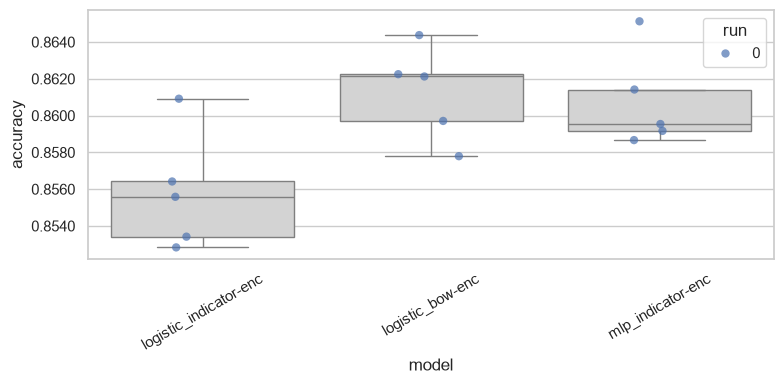

In [31]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

In [32]:
%%time
try:
    #from part1 import solutions
    my_classifiers['mlp_bow-enc'] = []
    for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
        run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
        my_classifiers['mlp_bow-enc'].append(
            part1.experiment.cross_validation_experiment(
                data_splits=my_cross_validation_sets[run],
                outcome_space=agnews_outcome_space,
                encoder=bow_encoder,
                model_option='mlp', 
                save_to=run_folder,
                smlp_args={
                    'hidden_dim': 128, 
                    'dropout': 0.1, 
                    'batch_size': 64, 
                    'learning_rate': 1e-4, 
                    'weight_decay': 1e-4, 
                    'num_epochs': 10,
                }
            )
        )
except ImportError:
    print("You need your own implementation of the bag-of-words encoder")

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 47.034 seconds
Dataloader done! Time taken: 1.518 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7304 | train acc: 0.7546 | val loss: 0.4666 | val acc: 0.8451
Epoch 02 | train loss: 0.4449 | train acc: 0.8467 | val loss: 0.4171 | val acc: 0.8584
Epoch 03 | train loss: 0.4113 | train acc: 0.8566 | val loss: 0.4022 | val acc: 0.8608
Epoch 04 | train loss: 0.3943 | train acc: 0.8620 | val loss: 0.3948 | val acc: 0.8622
Epoch 05 | train loss: 0.3824 | train acc: 0.8659 | val loss: 0.3882 | val acc: 0.8628
Epoch 06 | train loss: 0.3742 | train acc: 0.8681 | val loss: 0.3836 | val acc: 0.8641
Epoch 07 | train loss: 0.3640 | train acc: 0.8712 | val loss: 0.3801 | val acc: 0.8658
Epoch 08 | train loss: 0.3560 | train acc: 0.8746 | val loss: 0.3760 | val acc: 0.8662
Epoch 09 | train loss: 0.3476 | train acc: 0.8766 | val loss: 0.3712 | val acc: 0.8681
Epoch 10 | train loss: 0.3387 | train acc: 0.8803 | val loss: 0.3665 | val acc: 0.8688
Training done! Time taken: 152.032 seconds
Transforming documents...
Document transformation done! Time taken: 47.377 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7334 | train acc: 0.7526 | val loss: 0.4692 | val acc: 0.8423
Epoch 02 | train loss: 0.4445 | train acc: 0.8475 | val loss: 0.4196 | val acc: 0.8559
Epoch 03 | train loss: 0.4115 | train acc: 0.8577 | val loss: 0.4038 | val acc: 0.8601
Epoch 04 | train loss: 0.3947 | train acc: 0.8627 | val loss: 0.3962 | val acc: 0.8617
Epoch 05 | train loss: 0.3842 | train acc: 0.8661 | val loss: 0.3901 | val acc: 0.8629
Epoch 06 | train loss: 0.3730 | train acc: 0.8693 | val loss: 0.3856 | val acc: 0.8645
Epoch 07 | train loss: 0.3648 | train acc: 0.8717 | val loss: 0.3807 | val acc: 0.8664
Epoch 08 | train loss: 0.3556 | train acc: 0.8743 | val loss: 0.3774 | val acc: 0.8681
Epoch 09 | train loss: 0.3468 | train acc: 0.8789 | val loss: 0.3727 | val acc: 0.8686
Epoch 10 | train loss: 0.3377 | train acc: 0.8810 | val loss: 0.3677 | val acc: 0.8706
Training done! Time taken: 152.844 seconds
Transforming documents...
Document transformation done! Time taken: 47.174 seconds
Data

... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7361 | train acc: 0.7500 | val loss: 0.4753 | val acc: 0.8415
Epoch 02 | train loss: 0.4441 | train acc: 0.8479 | val loss: 0.4233 | val acc: 0.8540
Epoch 03 | train loss: 0.4101 | train acc: 0.8581 | val loss: 0.4074 | val acc: 0.8575
Epoch 04 | train loss: 0.3924 | train acc: 0.8636 | val loss: 0.3997 | val acc: 0.8592
Epoch 05 | train loss: 0.3810 | train acc: 0.8671 | val loss: 0.3938 | val acc: 0.8610
Epoch 06 | train loss: 0.3710 | train acc: 0.8706 | val loss: 0.3896 | val acc: 0.8618
Epoch 07 | train loss: 0.3631 | train acc: 0.8718 | val loss: 0.3853 | val acc: 0.8633
Epoch 08 | train loss: 0.3536 | train acc: 0.8760 | val loss: 0.3821 | val acc: 0.8640
Epoch 09 | train loss: 0.3456 | train acc: 0.8786 | val loss: 0.3766 | val acc: 0.8654
Epoch 10 | train loss: 0.3364 | train acc: 0.8822 | val loss: 0.3732 | val acc: 0.8669
Training done! Time taken: 162.462 seconds
Transforming documents...
Document transformation done! Time taken: 52.562 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.7276 | train acc: 0.7556 | val loss: 0.4725 | val acc: 0.8402
Epoch 02 | train loss: 0.4432 | train acc: 0.8479 | val loss: 0.4238 | val acc: 0.8530
Epoch 03 | train loss: 0.4087 | train acc: 0.8583 | val loss: 0.4085 | val acc: 0.8565
Epoch 04 | train loss: 0.3926 | train acc: 0.8628 | val loss: 0.4020 | val acc: 0.8581
Epoch 05 | train loss: 0.3811 | train acc: 0.8672 | val loss: 0.3971 | val acc: 0.8596
Epoch 06 | train loss: 0.3717 | train acc: 0.8698 | val loss: 0.3911 | val acc: 0.8612
Epoch 07 | train loss: 0.3630 | train acc: 0.8725 | val loss: 0.3872 | val acc: 0.8622
Epoch 08 | train loss: 0.3538 | train acc: 0.8751 | val loss: 0.3825 | val acc: 0.8636
Epoch 09 | train loss: 0.3456 | train acc: 0.8782 | val loss: 0.3783 | val acc: 0.8650
Epoch 10 | train loss: 0.3365 | train acc: 0.8819 | val loss: 0.3753 | val acc: 0.8673
Training done! Time taken: 161.288 seconds
CPU times: total: 1h 46min 58s
Wall time: 17min 8s


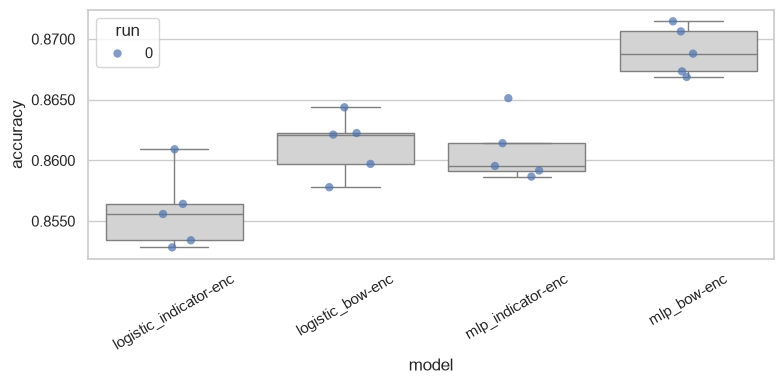

In [33]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

In [34]:
my_classifiers['logistic_tf-idf-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_tf-idf-enc/seed-{seed}"
    my_classifiers['logistic_tf-idf-enc'].append(
        part1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=tfidf_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1'

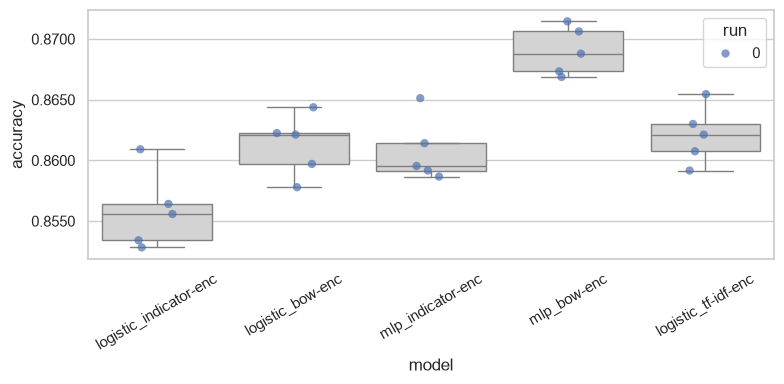

In [35]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

In [36]:
my_classifiers['logistic_bigram-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_bigram-enc/seed-{seed}"
    my_classifiers['logistic_bigram-enc'].append(
        part1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=agnews_outcome_space,
            encoder=constrained_bigram_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
d:\Assignments\nlp1-student\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:14

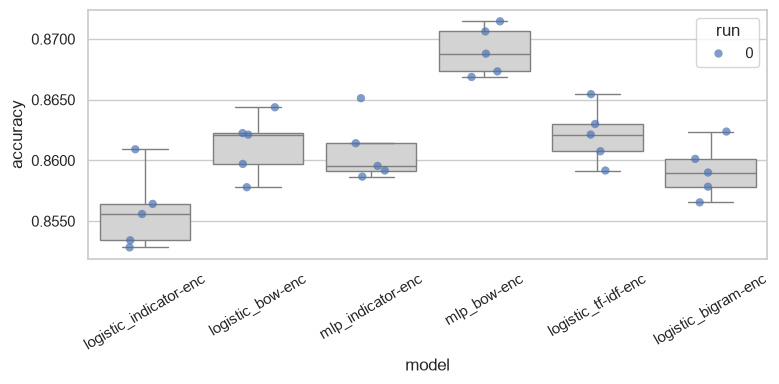

In [37]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

use fixed size of a sentence with embeddings to train an MLP to classify the class

In [38]:
from tqdm.notebook import tqdm
from datasets import load_dataset
import clslib

dataset = load_dataset("fancyzhx/ag_news")
agnews_outcome_space = clslib.NamedClasses(['world', 'sports', 'business', 'tech/sci-fi'])
vocab = {"<pad>": 0, "<unk>": 1}

unique_chars = set()
for text in dataset["train"]["text"]:
    unique_chars.update(text)

for char in sorted(unique_chars):
    if char not in vocab:
        vocab[char] = len(vocab)

print(f"Vocabulary size: {len(vocab)}")

MAX_LEN = 1000
PAD_ID = vocab["<pad>"]
UNK_ID = vocab["<unk>"]

def tokenize_characters(batch):
    all_input_ids = []
    all_attention_masks = []

    for text in batch["text"]:
        ids = [vocab.get(char, UNK_ID) for char in text]

        if len(ids) > MAX_LEN:
            ids = ids[:MAX_LEN]
            mask = [1] * MAX_LEN
        else:
            padding_length = MAX_LEN - len(ids)
            mask = [1] * len(ids) + [0] * padding_length
            ids = ids + [PAD_ID] * padding_length

        all_input_ids.append(ids)
        all_attention_masks.append(mask)

    return {"input_ids": all_input_ids, "attention_mask": all_attention_masks}

tokenized_dataset = dataset.map(
    tokenize_characters,
    batched=True,
    batch_size=1000
)


Vocabulary size: 84


In [39]:
import torch
import torch.nn as nn

class Model(nn.Module):
    def __init__(self, vocab_size, seq_len, embeddings_size, hidden_size, output_size, pad_idx=0):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, embeddings_size, padding_idx=pad_idx)
        
        self.conv1 = nn.Conv1d(in_channels=embeddings_size, out_channels=hidden_size, kernel_size=5, padding=2)
        self.conv2 = nn.Conv1d(in_channels=hidden_size, out_channels=hidden_size, kernel_size=5, padding=2)
        self.relu = nn.ReLU()
        
        self.global_pool = nn.AdaptiveMaxPool1d(1)
        
        self.MLP = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(hidden_size, output_size)
        )

    def forward(self, x):
        x = self.embeddings(x)
        x = x.transpose(1, 2)
        
        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))
        
        x = self.global_pool(x).squeeze(-1)
        return self.MLP(x)

In [40]:
from tqdm.notebook import tqdm
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

tokenized_dataset.set_format(type="torch", columns=["input_ids", "label"])

batch_size = 128
train_loader = DataLoader(tokenized_dataset["train"], batch_size=batch_size, shuffle=True)
test_loader = DataLoader(tokenized_dataset["test"], batch_size=256, shuffle=False)

device = torch.device(
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.backends.mps.is_available() 
    else "cpu"
)
print(f"Training on device: {device}")

net = Model(
    vocab_size=len(vocab),
    seq_len=1000,
    embeddings_size=32,
    hidden_size=128,
    output_size=4,
    pad_idx=PAD_ID
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

epochs = 5

for epoch in range(1, epochs + 1):
    net.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch}/{epochs} [Train]")
    for batch in progress_bar:
        inputs = batch["input_ids"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()
        logits = net(inputs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        preds = logits.argmax(dim=-1)
        correct_train += (preds == labels).sum().item()
        total_train += labels.size(0)

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{correct_train / total_train:.4f}"
        )

    train_loss = running_loss / total_train
    train_acc = correct_train / total_train

    net.eval()
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad():
        for batch in test_loader:
            inputs = batch["input_ids"].to(device)
            labels = batch["label"].to(device)

            logits = net(inputs)
            loss = criterion(logits, labels)

            running_test_loss += loss.item() * labels.size(0)
            preds = logits.argmax(dim=-1)
            correct_test += (preds == labels).sum().item()
            total_test += labels.size(0)

    test_loss = running_test_loss / total_test
    test_acc = correct_test / total_test

    print(
        f"Epoch {epoch}/{epochs} -> "
        f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2%} | "
        f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2%}"
    )

Training on device: cuda


Epoch 1/5 [Train]:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 1/5 -> Train Loss: 0.6864, Train Acc: 73.50% | Test Loss: 0.4062, Test Acc: 85.86%


Epoch 2/5 [Train]:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 2/5 -> Train Loss: 0.4749, Train Acc: 83.35% | Test Loss: 0.3421, Test Acc: 88.24%


Epoch 3/5 [Train]:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 3/5 -> Train Loss: 0.4313, Train Acc: 84.99% | Test Loss: 0.3192, Test Acc: 88.64%


Epoch 4/5 [Train]:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 4/5 -> Train Loss: 0.4019, Train Acc: 86.07% | Test Loss: 0.3078, Test Acc: 89.14%


Epoch 5/5 [Train]:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 5/5 -> Train Loss: 0.3848, Train Acc: 86.66% | Test Loss: 0.2946, Test Acc: 89.83%


In [41]:
from torch.utils.data import TensorDataset, DataLoader

def encode_pairs_to_tensors(pairs, vocab, max_len=1000, pad_id=0, unk_id=1):
    x_list, y_list = [], []
    for text, label in pairs:
        ids = [vocab.get(ch, unk_id) for ch in text]
        if len(ids) > max_len:
            ids = ids[:max_len]
        else:
            ids = ids + [pad_id] * (max_len - len(ids))
        x_list.append(ids)
        y_list.append(label)
    return torch.tensor(x_list, dtype=torch.long), torch.tensor(y_list, dtype=torch.long)


--- Running Seed 0 (5 folds) ---

[Fold 1/5]
  -> Fold 1 Validation Accuracy: 0.8930

[Fold 2/5]
  -> Fold 2 Validation Accuracy: 0.8995

[Fold 3/5]
  -> Fold 3 Validation Accuracy: 0.8948

[Fold 4/5]
  -> Fold 4 Validation Accuracy: 0.8922

[Fold 5/5]
  -> Fold 5 Validation Accuracy: 0.8878


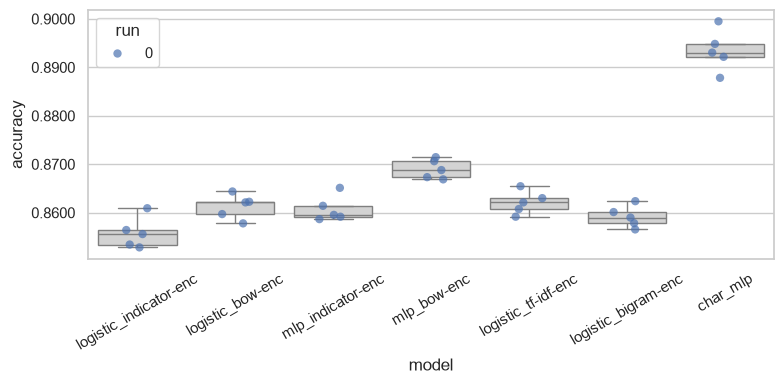

CPU times: total: 8min 20s
Wall time: 8min 3s


In [42]:
%%time
my_classifiers['char_mlp'] = []

num_epochs = 5
batch_size = 128

for run, seed in enumerate(my_seeds):
    fold_accuracies = {}
    folds = my_cross_validation_sets[run]
    
    fold_items = folds.items() if isinstance(folds, dict) else enumerate(folds)
    
    print(f"\n--- Running Seed {seed} ({len(folds)} folds) ---")
    
    for fold_idx, fold in fold_items:
        print(f"\n[Fold {fold_idx + 1}/{len(folds)}]")
        
        x_train, y_train = encode_pairs_to_tensors(fold["training"], vocab, max_len=MAX_LEN, pad_id=PAD_ID, unk_id=UNK_ID)
        x_val, y_val = encode_pairs_to_tensors(fold["validation"], vocab, max_len=MAX_LEN, pad_id=PAD_ID, unk_id=UNK_ID)
        
        train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(TensorDataset(x_val, y_val), batch_size=256, shuffle=False)
        
        fold_model = Model(
            vocab_size=len(vocab),
            seq_len=MAX_LEN,
            embeddings_size=32,
            hidden_size=128,
            output_size=len(agnews_outcome_space),
            pad_idx=PAD_ID
        ).to(device)
        
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(fold_model.parameters(), lr=1e-3)
        
        for epoch in range(1, num_epochs + 1):
            fold_model.train()
            running_loss = 0.0
            correct = 0
            total = 0
            
            for x_batch, y_batch in train_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                
                optimizer.zero_grad()
                logits = fold_model(x_batch)
                loss = criterion(logits, y_batch)
                loss.backward()
                optimizer.step()
                
                running_loss += loss.item() * y_batch.size(0)
                preds = logits.argmax(dim=-1)
                correct += (preds == y_batch).sum().item()
                total += y_batch.size(0)
                
            train_acc = correct / total

        fold_model.eval()
        correct_val = 0
        total_val = 0
        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                preds = fold_model(x_batch).argmax(dim=-1)
                correct_val += (preds == y_batch).sum().item()
                total_val += y_batch.size(0)
                
        val_acc = correct_val / total_val
        fold_accuracies[fold_idx] = val_acc
        print(f"  -> Fold {fold_idx + 1} Validation Accuracy: {val_acc:.4f}")
    
    my_classifiers['char_mlp'].append({'accuracies': fold_accuracies})

df_results = part1.analysis.make_data_frame(my_classifiers)
part1.analysis.plot_box_and_points(df_results)

Comparing systems: ['logistic_indicator-enc', 'logistic_bow-enc', 'mlp_indicator-enc', 'mlp_bow-enc', 'logistic_tf-idf-enc', 'logistic_bigram-enc', 'char_mlp']



,System A,System B,Mean Diff (B - A),P(A wins),P(Practical Equiv / ROPE),P(B wins),Effect Size
0,logistic_indicator-enc,logistic_bow-enc,+0.0054,0.0002,0.3456,0.6541,5.54
1,logistic_indicator-enc,mlp_indicator-enc,+0.0049,0.0001,0.5260,0.4739,6.90
2,logistic_indicator-enc,mlp_bow-enc,+0.0132,0.0000,0.0007,0.9993,12.53
3,logistic_indicator-enc,logistic_tf-idf-enc,+0.0063,0.0001,0.1212,0.8787,6.78
4,logistic_indicator-enc,logistic_bigram-enc,+0.0033,0.0002,0.9543,0.0455,4.47
5,logistic_indicator-enc,char_mlp,+0.0376,0.0000,0.0001,0.9999,15.60
6,logistic_bow-enc,mlp_indicator-enc,-0.0005,0.0101,0.9846,0.0054,-0.38
7,logistic_bow-enc,mlp_bow-enc,+0.0078,0.0000,0.0067,0.9933,11.88
8,logistic_bow-enc,logistic_tf-idf-enc,+0.0009,0.0001,0.9997,0.0002,2.21
9,logistic_bow-enc,logistic_bigram-enc,-0.0021,0.0143,0.9851,0.0006,-2.38


Comparison: logistic_indicator-enc vs logistic_bow-enc


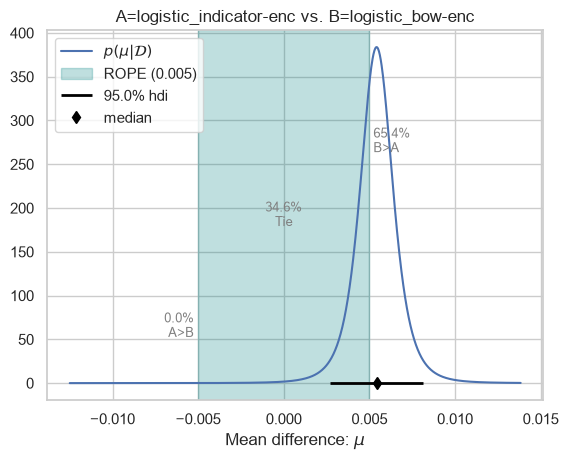

Comparison: logistic_indicator-enc vs mlp_indicator-enc


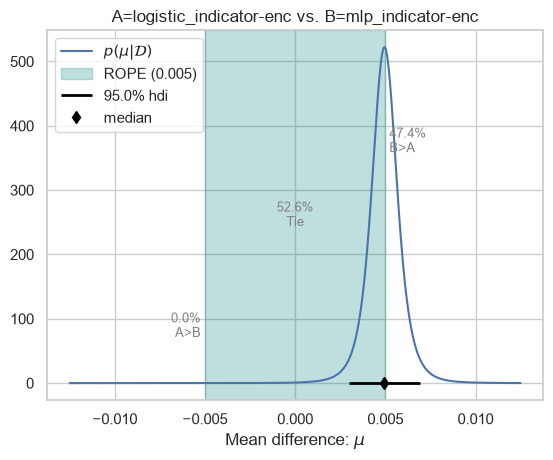

Comparison: logistic_indicator-enc vs mlp_bow-enc


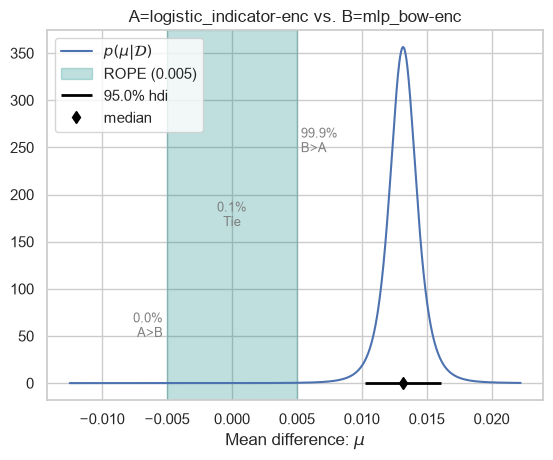

Comparison: logistic_indicator-enc vs logistic_tf-idf-enc


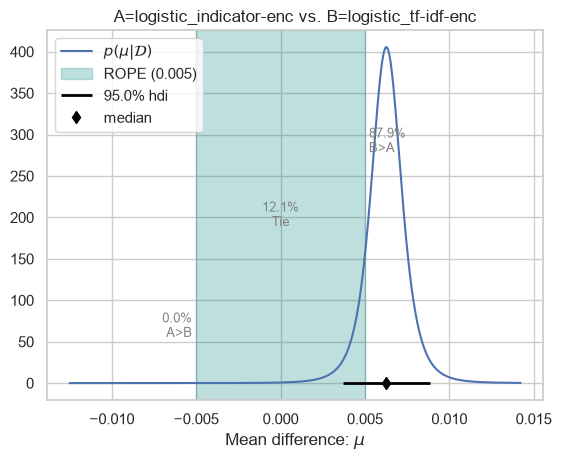

Comparison: logistic_indicator-enc vs logistic_bigram-enc


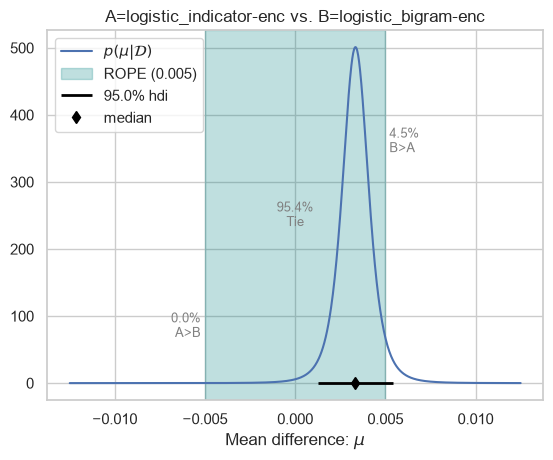

Comparison: logistic_indicator-enc vs char_mlp


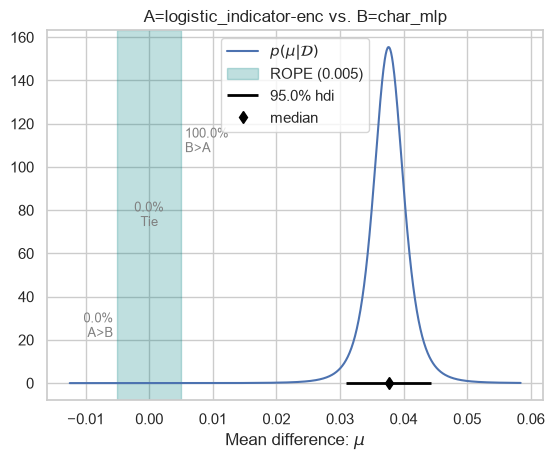

Comparison: logistic_bow-enc vs mlp_indicator-enc


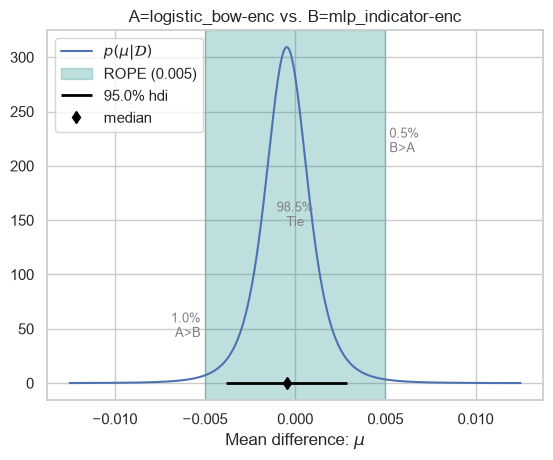

Comparison: logistic_bow-enc vs mlp_bow-enc


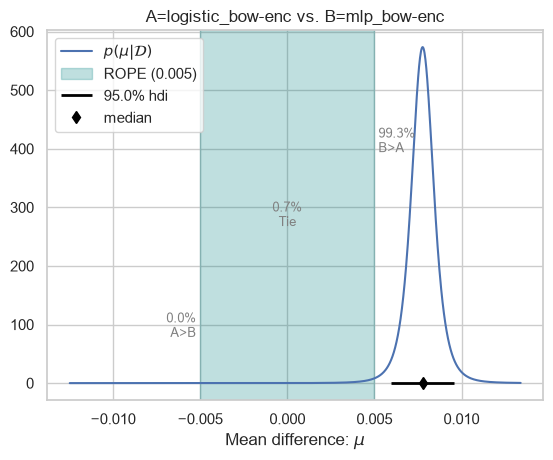

Comparison: logistic_bow-enc vs logistic_tf-idf-enc


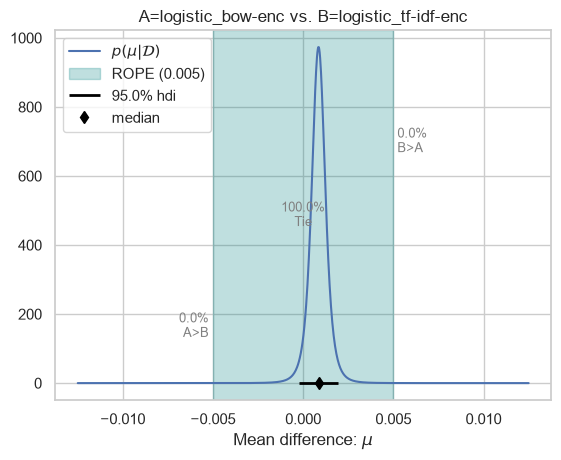

Comparison: logistic_bow-enc vs logistic_bigram-enc


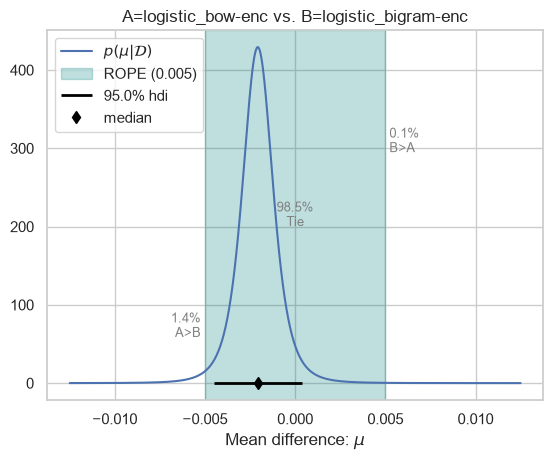

Comparison: logistic_bow-enc vs char_mlp


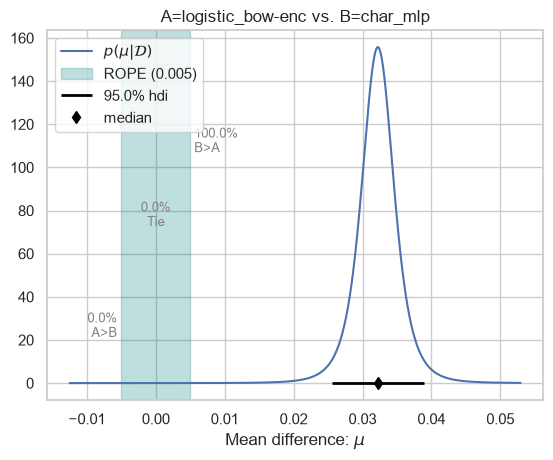

Comparison: mlp_indicator-enc vs mlp_bow-enc


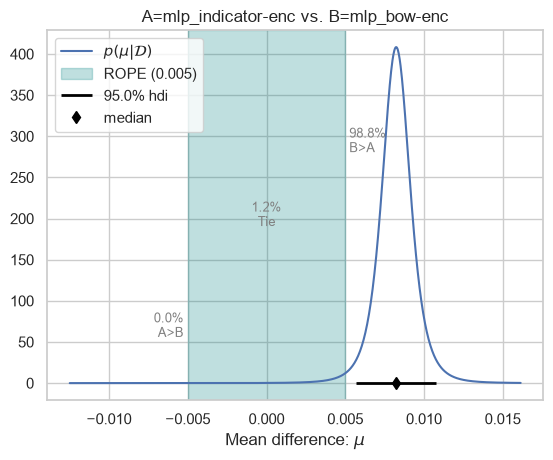

Comparison: mlp_indicator-enc vs logistic_tf-idf-enc


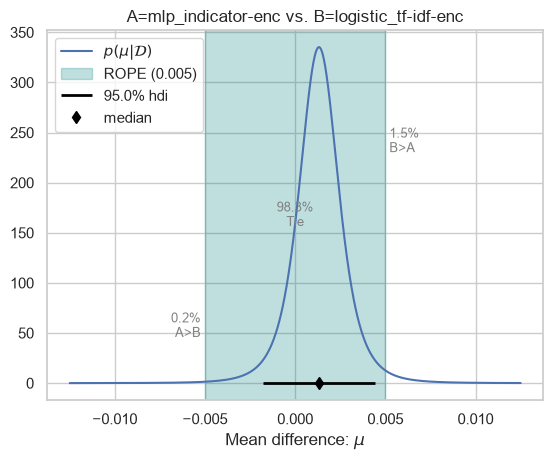

Comparison: mlp_indicator-enc vs logistic_bigram-enc


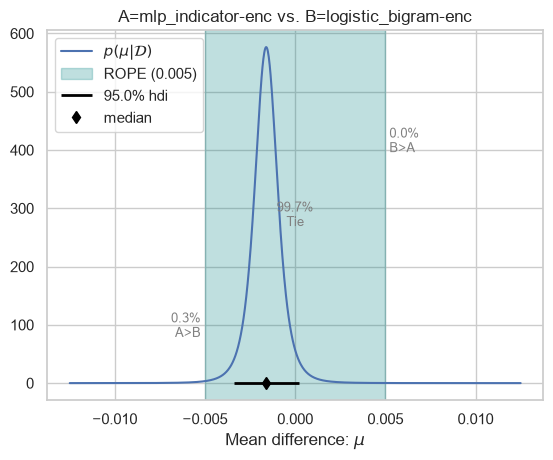

Comparison: mlp_indicator-enc vs char_mlp


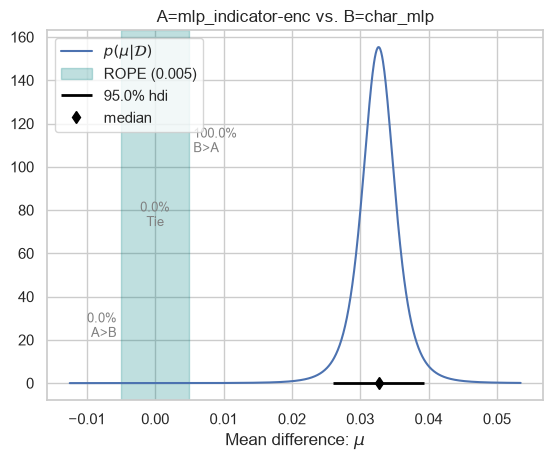

Comparison: mlp_bow-enc vs logistic_tf-idf-enc


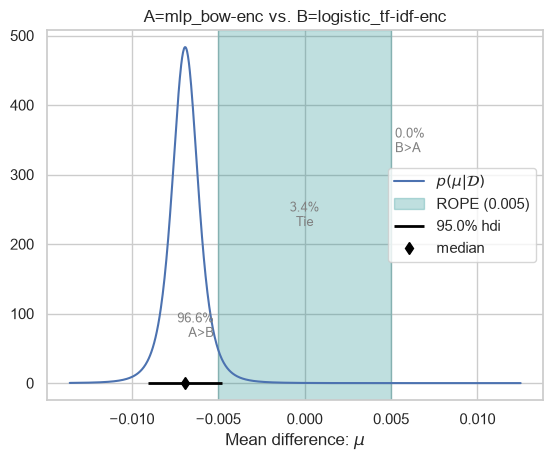

Comparison: mlp_bow-enc vs logistic_bigram-enc


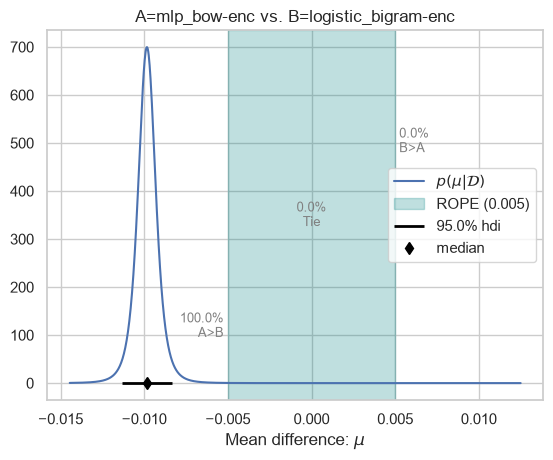

Comparison: mlp_bow-enc vs char_mlp


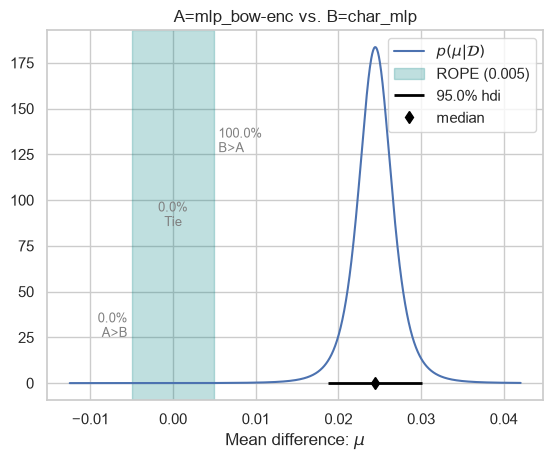

Comparison: logistic_tf-idf-enc vs logistic_bigram-enc


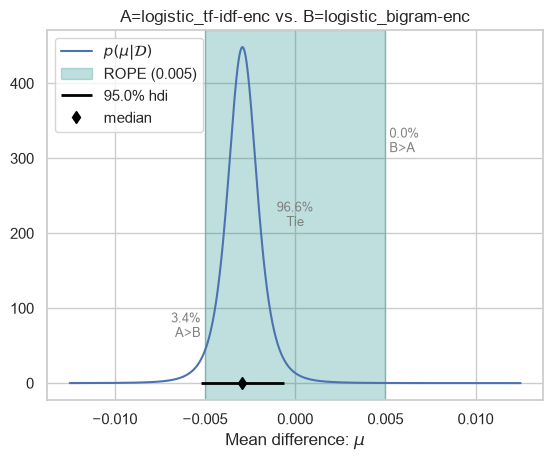

Comparison: logistic_tf-idf-enc vs char_mlp


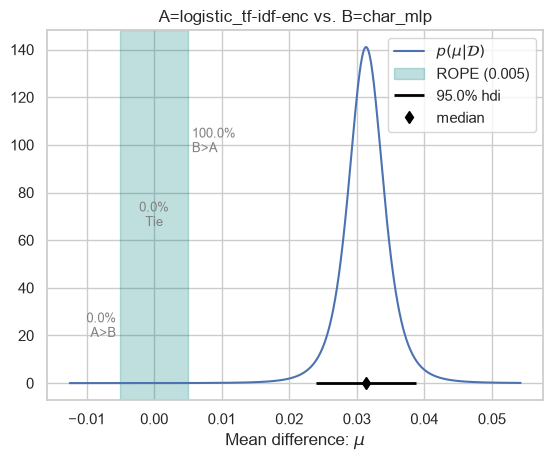

Comparison: logistic_bigram-enc vs char_mlp


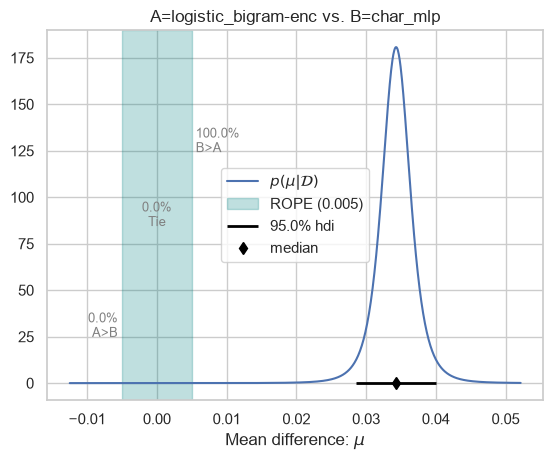

In [43]:
# %%
import itertools
import pandas as pd
import matplotlib.pyplot as plt

def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

ROPE_SIZE = 0.005  

pairwise_results = []
all_posteriors = {}

system_names = list(my_classifiers.keys())
print(f"Comparing systems: {system_names}\n")

for sys_a, sys_b in itertools.combinations(system_names, 2):
    measurements_a = get_all_measurements_for(my_classifiers, sys_a).flatten()
    measurements_b = get_all_measurements_for(my_classifiers, sys_b).flatten()
    
    posterior = part1.analysis.BenavoliCorrelatedT(
        measurements_a,
        measurements_b,
        names=[sys_a, sys_b]
    )
    all_posteriors[f"{sys_a} vs {sys_b}"] = posterior
    
    p_a, p_tie, p_b = posterior.probs(ROPE_SIZE)
    mean_diff = np.mean(measurements_b) - np.mean(measurements_a)
    
    pairwise_results.append({
        "System A": sys_a,
        "System B": sys_b,
        "Mean Diff (B - A)": f"{mean_diff:+.4f}",
        "P(A wins)": round(p_a, 4),
        "P(Practical Equiv / ROPE)": round(p_tie, 4),
        "P(B wins)": round(p_b, 4),
        "Effect Size": round(posterior.effect_size, 2)
    })

df_bayesian = pd.DataFrame(pairwise_results)
display(df_bayesian)

for pair_name, posterior in all_posteriors.items():
    print(f"Comparison: {pair_name}")
    _ = posterior.plot(ROPE_SIZE)
    plt.show()